# Proč dron letí, pokročilá verze: výkon v dopředném letu, vítr, hustota vzduchu a vliv země

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Proč dron letí](https://openskylab.space/edu_viz_why_drones_fly.html) · [English version](why_drones_fly_pro_en.ipynb)

Pokročilá verze notebooku o letu dronu. Mavic 3E podle výrobce visí 38 minut, ale stálou rychlostí 32,4 km/h letí 45 minut: v dopředném letu tedy potřebuje méně výkonu než na místě. Sestavíš model výkonu z teorie hybnosti, nakalibruješ ho na tyto dva údaje a použiješ ho na nejlepší rychlost pro výdrž a dolet, na skutečný vítr ve 120 m za poslední tři měsíce, na hustotu vzduchu a na let těsně nad zemí.

**Cíl:** rozložit výkon dronu na indukovaný, profilový a škodlivý, nakalibrovat model na údaje výrobce, najít rychlost nejdelší výdrže a největšího doletu i s protivětrem, vyhodnotit skutečný vítr a hustotu vzduchu za 92 dní a odhadnout vliv země při visení nízko.

**Data:** hodinový vítr v 10 a 120 m, teplota, vlhkost a tlak za posledních 92 dní z Open-Meteo pro Roztoky (modelová data, ne měření); hmotnost, vrtule, baterie a výdrž Mavicu 3E z technického listu DJI (45 min letu stálou rychlostí 32,4 km/h bez větru u hladiny moře do vybití, 38 min visení). Účinnost rotoru FM, indukční ztráty a obvodová rychlost listu jsou odhady; účinnost pohonu a plochu odporu notebook dopočítá kalibrací, takže v nich jsou schované i všechny ostatní ztráty (elektronika, kamera, baterie).

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 55 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

## 2. Model výkonu a jeho kalibrace

Výkon rozložíme na tři části. **Indukovaný** výkon jde na urychlení vzduchu dolů; v dopředném letu proudí diskem víc vzduchu, takže stačí menší indukovaná rychlost (Glauert). **Profilový** výkon spotřebuje odpor listů vrtule a s rychlostí mírně roste. **Škodlivý** výkon překonává odpor trupu a roste s třetí mocninou rychlosti. Dvě neznámé, účinnost pohonu η a ekvivalentní plochu odporu f, určíme z výdrže při visení a při letu 9 m/s.

In [2]:
g = 9.81
# Mavic 3E z technického listu DJI: vzletová hmotnost, vrtule 9,4″, baterie, výdrž
m, n_rot, R, E_BAT = 0.915, 4, 9.4 * 0.0254 / 2, 77.0
T_HOVER, T_FLIGHT, V_TEST = 38, 45, 32.4 / 3.6     # min visení; min letu stálou rychlostí 32,4 km/h; ta rychlost v m/s
A = n_rot * np.pi * R ** 2                          # plocha všech disků
W = m * g
RHO0 = 1.225                                        # hustota standardní atmosféry u hladiny moře (kg/m³)
KAPPA = 1.15     # ◀ parametr: indukční ztráty proti ideálnímu disku (nerovnoměrný tok, konec listu)
FM = 0.60        # ◀ parametr: účinnost rotoru při visení (figure of merit)
V_TIP = 90.0     # ◀ parametr: obvodová rychlost konce listu (m/s), odhad
K_P = 4.65       # nárůst profilového výkonu s dopřednou rychlostí (Leishman 2006)

def induced_velocity(T, V, alpha, rho):
    """Indukovaná rychlost v dopředném letu podle Glauerta (rotor skloněný o alpha)."""
    vh = np.sqrt(T / (2 * rho * A))
    return brentq(lambda v: v - vh ** 2 / np.hypot(V * np.cos(alpha), V * np.sin(alpha) + v), 1e-6, 2 * vh)

def power(V, rho, fA, eta, mass=m):
    """Elektrický výkon (W) při vodorovném letu rychlostí V vůči vzduchu: indukovaný, profilový, škodlivý."""
    Wt = mass * g
    D = 0.5 * rho * V ** 2 * fA                     # odpor trupu
    T = np.hypot(Wt, D); alpha = np.arctan2(D, Wt)  # tah a náklon
    Pi_h = Wt * np.sqrt(Wt / (2 * rho * A))         # ideální výkon při visení
    Pi = KAPPA * T * induced_velocity(T, V, alpha, rho)
    P0 = (1 / FM - KAPPA) * Pi_h * (1 + K_P * (V / V_TIP) ** 2)
    Pp = D * V
    return np.array([Pi, P0, Pp]) / eta

# kalibrace na údaje výrobce: výkon při visení určí účinnost pohonu, výkon při 9 m/s plochu odporu
P_hover, P_test = E_BAT / (T_HOVER / 60), E_BAT / (T_FLIGHT / 60)
eta = W * np.sqrt(W / (2 * RHO0 * A)) / FM / P_hover
fA = brentq(lambda f: power(V_TEST, RHO0, f, eta).sum() - P_test, 1e-5, 0.5)
print(f"výkon z výdrže: visení {P_hover:.1f} W, let {V_TEST:.0f} m/s {P_test:.1f} W")
print(f"kalibrace: účinnost pohonu a elektroniky η = {eta:.2f}, ekvivalentní plocha odporu f = Cd·S = {fA * 1e4:.0f} cm²")

výkon z výdrže: visení 121.6 W, let 9 m/s 102.7 W
kalibrace: účinnost pohonu a elektroniky η = 0.56, ekvivalentní plocha odporu f = Cd·S = 282 cm²


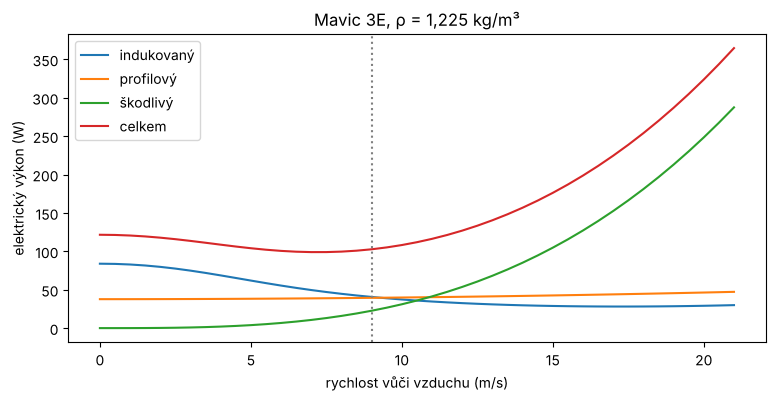

nejmenší výkon 99 W při 7.0 m/s → výdrž 47 min
nejmenší energie na km 2.93 Wh/km při 11.5 m/s → dolet 26.3 km


,indukovaný,profilový,škodlivý,celkem
0.0,83.9,37.7,0.0,121.6
2.0,79.8,37.8,0.2,117.8
4.0,68.7,38.0,2.0,108.7
6.0,55.4,38.5,6.7,100.6
8.0,44.7,39.1,15.9,99.6
10.0,37.3,39.9,31.0,108.2
12.0,32.5,40.8,53.6,127.0
14.0,29.7,41.9,85.2,156.8
16.0,28.3,43.2,127.2,198.7
18.0,28.2,44.7,181.1,253.9


In [3]:
Vs = np.arange(0, 21.5, 0.5)
curve = pd.DataFrame([power(V, RHO0, fA, eta) for V in Vs], index=Vs, columns=["indukovaný", "profilový", "škodlivý"])
curve["celkem"] = curve.sum(axis=1)
V_end = curve["celkem"].idxmin()
V_rng = (curve["celkem"] / curve.index.to_series().replace(0, np.nan)).idxmin()
ax = curve.plot(figsize=(9, 4)); ax.axvline(V_TEST, color="gray", ls=":")
ax.set(xlabel="rychlost vůči vzduchu (m/s)", ylabel="elektrický výkon (W)", title="Mavic 3E, ρ = 1,225 kg/m³"); plt.show()
print(f"nejmenší výkon {curve['celkem'].min():.0f} W při {V_end:.1f} m/s → výdrž {E_BAT / curve['celkem'].min() * 60:.0f} min")
print(f"nejmenší energie na km {curve['celkem'][V_rng] / V_rng / 3.6:.2f} Wh/km při {V_rng:.1f} m/s → dolet {E_BAT / (curve['celkem'][V_rng] / V_rng / 3.6):.1f} km")
curve.iloc[::4].round(1)

> **✏️ Úkol 1.** Proč indukovaný výkon s rychlostí klesá a škodlivý roste? Při jaké rychlosti má dron nejdelší výdrž a při jaké největší dolet, a proč to nejsou stejné rychlosti? Je ekvivalentní plocha odporu f věrohodná pro dron velikosti Mavicu (odhadni čelní plochu trupu a součinitel odporu kolem 1)? Změň `FM` na 0,5 a 0,7: jak se změní kalibrace a výsledné rychlosti?

*Tvoje odpověď:* 

## 3. Let proti větru

Při protivětru se počítá energie na kilometr vůči zemi: výkon dělený rychlostí vůči zemi (V − vítr). Tabulka ukazuje nejlepší rychlost vůči vzduchu pro různý protivítr a srovnání se stálými 9 m/s.

In [4]:
rows = []
for wind in [0, 3, 6, 9, 12]:                      # vítr proti směru letu (m/s)
    Vv = Vs[Vs > wind + 0.5]
    e = np.array([power(V, RHO0, fA, eta).sum() / (V - wind) / 3.6 for V in Vv])   # Wh na km vůči zemi
    k = e.argmin()
    rows.append({"protivítr (m/s)": wind, "nejlepší rychlost vůči vzduchu (m/s)": Vv[k], "rychlost vůči zemi (m/s)": Vv[k] - wind,
                 "energie (Wh/km)": e[k], "při stálých 9 m/s (Wh/km)": power(9, RHO0, fA, eta).sum() / (9 - wind) / 3.6 if wind < 9 else np.inf})
pd.DataFrame(rows).set_index("protivítr (m/s)").round(2)

,nejlepší rychlost vůči vzduchu (m/s),rychlost vůči zemi (m/s),energie (Wh/km),při stálých 9 m/s (Wh/km)
protivítr (m/s),,,,
0,11.5,11.5,2.93,3.17
3,12.5,9.5,3.90,4.75
6,14.5,8.5,5.43,9.51
9,17.0,8.0,7.80,inf
12,20.5,8.5,11.23,inf


> **✏️ Úkol 2.** Proč má dron při protivětru letět rychleji vůči vzduchu, i když tím roste výkon? Kolikrát víc energie na kilometr spotřebuje návrat proti větru 6 m/s, když letí optimální rychlostí, a kolikrát, když drží 9 m/s? Při jakém větru přestane stačit normální režim s rychlostí 15 m/s?

*Tvoje odpověď:* 

## 4. Skutečný vítr za poslední tři měsíce

Z Open-Meteo stáhneme hodinový vítr v 10 a 120 m a počasí za 92 dní pro Roztoky a vybereme denní hodiny 8–18 h. Pro každou hodinu spočítáme energii na kilometr návratu, kdyby celý vítr ve 120 m foukal proti.

Open-Meteo: SSLError – zkusím znovu


825 denních hodin s daty za 92 dní, vítr ve 120 m: medián 4.0 m/s, 90. percentil 8.4 m/s
  vítr ve 120 m nad  6.0 m/s: 29.7% hodin, v 10 m:  2.2%
  vítr ve 120 m nad  9.0 m/s:  6.7% hodin, v 10 m:  0.0%
  vítr ve 120 m nad 12.0 m/s:  0.6% hodin, v 10 m:  0.0%
energie na km návratu proti větru ve 120 m: medián 4.34 Wh/km, 90. percentil 7.22 Wh/km (bez větru 2.93)


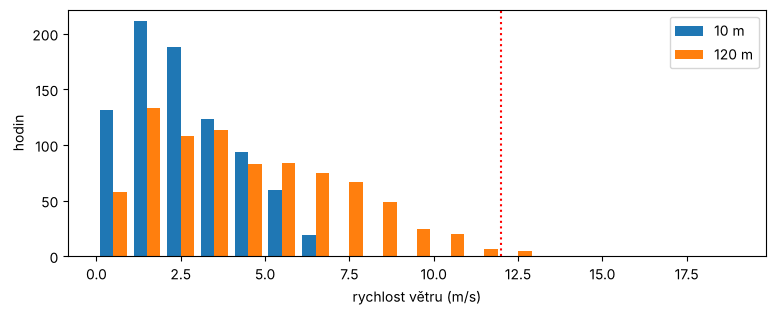

In [5]:
LAT, LON = 50.152, 14.392           # ◀ parametr: místo (Roztoky)
w = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms",
                "hourly": "wind_speed_10m,wind_speed_120m,temperature_2m,relative_humidity_2m,surface_pressure", "timezone": "Europe/Prague"})
met = pd.DataFrame(w["hourly"]).set_index("time"); met.index = pd.to_datetime(met.index)
day = met[(met.index.hour >= 8) & (met.index.hour <= 18)].dropna()   # jen hodiny, kdy se obvykle létá
WIND_LIMIT = 12.0                   # ◀ parametr: odolnost vůči větru podle výrobce (m/s)
print(f"{len(day)} denních hodin s daty za 92 dní, vítr ve 120 m: medián {day.wind_speed_120m.median():.1f} m/s, 90. percentil {day.wind_speed_120m.quantile(0.9):.1f} m/s")
for thr in [6, 9, WIND_LIMIT]:
    print(f"  vítr ve 120 m nad {thr:4.1f} m/s: {np.mean(day.wind_speed_120m > thr):5.1%} hodin, v 10 m: {np.mean(day.wind_speed_10m > thr):5.1%}")
best = {wv: min(power(V, RHO0, fA, eta).sum() / (V - wv) / 3.6 for V in Vs[Vs > wv + 0.5]) for wv in np.arange(0, 16, 0.5)}
e_back = np.interp(day.wind_speed_120m, list(best), list(best.values()))
print(f"energie na km návratu proti větru ve 120 m: medián {np.median(e_back):.2f} Wh/km, 90. percentil {np.percentile(e_back, 90):.2f} Wh/km (bez větru {best[0]:.2f})")
plt.figure(figsize=(9, 3.2)); plt.hist([day.wind_speed_10m, day.wind_speed_120m], bins=np.arange(0, 20, 1), label=["10 m", "120 m"])
plt.axvline(WIND_LIMIT, color="r", ls=":"); plt.xlabel("rychlost větru (m/s)"); plt.ylabel("hodin"); plt.legend(); plt.show()

> **✏️ Úkol 3.** Jak se liší vítr v 10 a ve 120 m a co to znamená, když vítr odhaduješ u země před vzletem? V kolika procentech denních hodin by vítr ve 120 m překročil odolnost dronu? O kolik procent víc energie na kilometr spotřebuje typický návrat proti větru proti bezvětří a co z toho plyne pro rezervu baterie?

*Tvoje odpověď:* 

## 5. Hustota vzduchu

Z tlaku, teploty a vlhkosti spočítáme hustotu vzduchu v Roztokách za stejných 92 dní a přidáme hustotu pro vysoké hory. Předpokládáme, že účinnost rotoru FM a pohonu η se s hustotou nemění.

In [6]:
met = met.dropna()
T = met.temperature_2m + 273.15
e_v = met.relative_humidity_2m / 100 * 6.112 * np.exp(17.62 * met.temperature_2m / (243.12 + met.temperature_2m))
rho = met.surface_pressure * 100 / (287.05 * T / (1 - 0.378 * e_v / met.surface_pressure))
RHO_MOUNTAIN = 0.90                 # ◀ parametr: hustota pro vysoké hory (kg/m³), zhruba 2600 m n. m.
cases = {"nejhustší (Roztoky)": rho.max(), "nejřidší (Roztoky)": rho.min(), "hory": RHO_MOUNTAIN}
rows = {}
for name, r in cases.items():
    P = np.array([power(V, r, fA, eta).sum() for V in Vs])
    k_end, k_rng = P.argmin(), (P[1:] / Vs[1:]).argmin() + 1
    rows[name] = {"ρ (kg/m³)": r, "visení (W)": P[0], "visení (min)": E_BAT / P[0] * 60, "nejmenší výkon (W)": P[k_end],
                  "rychlost nejdelší výdrže (m/s)": Vs[k_end], "rychlost největšího doletu (m/s)": Vs[k_rng], "dolet (km)": E_BAT / (P[k_rng] / Vs[k_rng] / 3.6)}
pd.DataFrame(rows).T.round(2)

,ρ (kg/m³),visení (W),visení (min),nejmenší výkon (W),rychlost nejdelší výdrže (m/s),rychlost největšího doletu (m/s),dolet (km)
nejhustší (Roztoky),1.27,119.43,38.68,97.16,7.0,11.0,26.29
nejřidší (Roztoky),1.12,127.11,36.35,103.54,7.5,12.0,26.23
hory,0.90,141.84,32.57,115.91,8.5,13.5,26.06


> **✏️ Úkol 4.** O kolik se v řidším vzduchu zkrátí doba visení a jak se posunou rychlosti nejdelší výdrže a největšího doletu? Proč se dolet v horách téměř nemění, i když výkon roste? (Porovnej, jak na hustotě závisí indukovaný a škodlivý výkon.) Co by se stalo, kdyby dron ve stejných horách nesl náklad, který zvýší hmotnost o 20 %? Zkus `m` v buňce modelu.

*Tvoje odpověď:* 

## 6. Visení těsně nad zemí

Blízko země se proud pod rotorem nemůže volně rozšířit, indukovaná rychlost klesne a stejný tah stojí méně výkonu. Cheeseman a Bennett (1955) to popsali vztahem v_IGE / v_OGE = 1 − (R / 4z)², kde z je výška rotoru nad zemí. Vztah platí pro jeden rotor; u kvadrokoptéry se proudy čtyř vrtulí navíc ovlivňují.

In [7]:
def ground_factor(z):
    """Cheeseman a Bennett (1955): poměr indukované rychlosti v blízkosti země a mimo ni při stejném tahu."""
    return np.clip(1 - (R / (4 * z)) ** 2, 0, 1)

rows = []
Pi_h, P0_h, _ = power(0, RHO0, fA, eta)
for zR in [0.5, 0.75, 1, 1.5, 2, 3, 5]:          # výška rotoru nad zemí v poloměrech
    k = ground_factor(zR * R)
    P = Pi_h * k + P0_h
    rows.append({"z / R": zR, "z (cm)": zR * R * 100, "indukovaná rychlost (% mimo zem)": k * 100, "výkon (W)": P, "úspora výkonu (%)": (1 - P / (Pi_h + P0_h)) * 100})
pd.DataFrame(rows).set_index("z / R").round(1)

,z (cm),indukovaná rychlost (% mimo zem),výkon (W),úspora výkonu (%)
z / R,,,,
0.50,6.0,75.0,100.6,17.3
0.75,9.0,88.9,112.3,7.7
1.00,11.9,93.8,116.3,4.3
1.50,17.9,97.2,119.2,1.9
2.00,23.9,98.4,120.3,1.1
3.00,35.8,99.3,121.0,0.5
5.00,59.7,99.8,121.4,0.2


> **✏️ Úkol 5.** Do jaké výšky nad zemí je vliv země u Mavicu znatelný (úspora výkonu nad 2 %)? Proč dron při přistání těsně nad zemí „plave“ a proč je to u velkých vrtulí výraznější v metrech? Proč ti vliv země nepomůže při letu nad vysokou vegetací nebo nad vodou se zvlněnou hladinou stejně jako nad betonem?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Uprav model na Matrice 350 RTK (hmotnost 6,47 kg, vrtule 21″, baterie 2 × 263 Wh). Výrobce udává 55 min letu bez nákladu; doplň `T_FLIGHT`, odhadni `T_HOVER` a sleduj, jak výdrž klesá s nákladem až do maximální vzletové hmotnosti 9,2 kg.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Počasí: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- DJI: *Mavic 3 Enterprise, specifikace* (https://enterprise.dji.com/mavic-3-enterprise/specs): vzletová hmotnost 915 g, baterie 77 Wh, max. doba letu 45 min a max. doba visení 38 min bez větru, odolnost vůči větru 12 m/s, max. rychlost 15 m/s v normálním a 21 m/s ve sportovním režimu. Podmínky měření 45 min (stálá rychlost 32,4 km/h u hladiny moře do vybití) uvádějí technické listy prodejců.
- Leishman, J. G. (2006). *Principles of Helicopter Aerodynamics*, 2. vyd. Cambridge University Press (teorie hybnosti v dopředném letu, rozklad výkonu, K ≈ 4,65).
- Glauert, H. (1926). A general theory of the autogyro. *ARC R&M* 1111 (indukovaná rychlost v dopředném letu).
- Cheeseman, I. C., Bennett, W. E. (1955). The effect of the ground on a helicopter rotor in forward flight. *ARC R&M* 3021.
- Hustota vlhkého vzduchu přes virtuální teplotu; tlak nasycených par Magnusovým vzorcem (WMO-No. 8, 2018).

### Jak citovat

OpenSkyLab (2026). Proč dron letí, pokročilá verze: výkon v dopředném letu, vítr, hustota vzduchu a vliv země [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*